# Exercise 3.b

- Invent an exercise where you have a random variable X with alphabet X with at least 4 outcomes, where each outcome has an inteher value (“cost”).
- Fix the mean value bigger than the arithmetic average of the costs, and apply the principle of maximum entropy to find the probability distribution P(X)
- Plot P(X)

- Repeat with a mean value equal to the arithmetic average and plot the result

- Repeat with other values of the mean value and plot the results

- Comment the results

In [39]:
import numpy as np
import matplotlib.pyplot as plt
# selecting arbitrary alphabets with size of 4
X = [3,6,1,5]
print("The arithmetic mean is:", np.mean(X))
# define a Mean value that higher than the arithmetic mean !! BUT LOWER THAN THE MAXIMUM VALUE !!
Mean = 3
# 

The arithmetic mean is: 3.75


$$ \sum_{i=1}^{n} \beta^{x_i} x_i = \mu (\sum_{i=1}^{n} \beta^{x_i}) $$

In [51]:
import numpy as np
from scipy.optimize import root_scalar

def calculate_beta(x, mu):
    """
    Solve for beta given x and a constant mu in the equation:
    Sum (beta^x_i * x_i) = mu * Sum (beta^x_i)
    
    Parameters:
    x : list or numpy array of x values
    mu : a constant value of mu (e.g., 2.5)
    
    Returns:
    beta : the value of beta that satisfies the equation
    """
    n = len(x)  # Length of x determines the number of terms in the sum
    
    # Define the equation to be solved for beta
    def equation_to_solve(beta):
        left_side = sum([beta ** x_i * x_i for x_i in x])
        right_side = mu * sum([beta ** x_i for x_i in x])
        return left_side - right_side
    
    # Use a root-finding method to solve the equation numerically
    result = root_scalar(equation_to_solve, bracket=[0.1, 10], method='brentq')
    
    if result.converged:
        return result.root
    else:
        raise ValueError("Could not find a solution for beta.")

# Example usage
x = [3,6,1,5]  # Example values for x
mu = 5 # Given constant value for mu

# Calculate beta
beta = calculate_beta(x, mu)
print(f"The calculated value of beta is: {beta}")

The calculated value of beta is: 1.5436890126920761


## probability distribution base on Beta 

$$ P(x_i) = \frac{\beta^{x_i}}{\sum_{i=1}^{n} \beta^{x_i}} $$

In [52]:
# calculate the probability base on the beta and x
def calculate_probability(x, beta):
    """
    Calculate the probability of each x value given a beta value.
    
    Parameters:
    x : list or numpy array of x values
    beta : the value of beta
    
    Returns:
    probabilities : a list of probabilities for each x value
    """
    # Calculate the denominator for the probabilities
    denominator = sum([beta ** x_i for x_i in x])
    
    # Calculate the probability for each x value
    probabilities = [(beta ** x_i) / denominator for x_i in x]
    
    return probabilities


# Calculate the probabilities for the example x values and beta
probabilities = calculate_probability(x, beta)

# Print the calculated probabilities
for i, prob in enumerate(probabilities):
    print(f"Probability of x={x[i]} is: {prob:.4f}")

Probability of x=3 is: 0.1337
Probability of x=6 is: 0.4917
Probability of x=1 is: 0.0561
Probability of x=5 is: 0.3185


Text(0.5, 1.0, 'Probability Of Each x Value based on Mu=5')

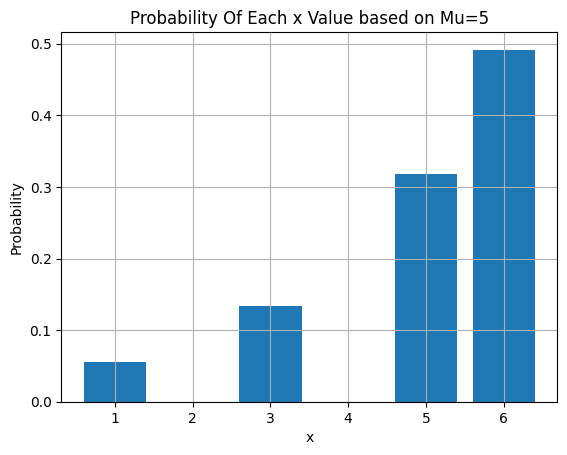

In [53]:
# plot 
plt.bar(x, probabilities)
plt.grid()
plt.xlabel('X Values')
plt.ylabel('Probability')
plt.title(f'Probability Of Each x Value based on Mu={mu}')


Text(0.5, 1.0, 'Probability Of Each x Value based on Mu=3.75')

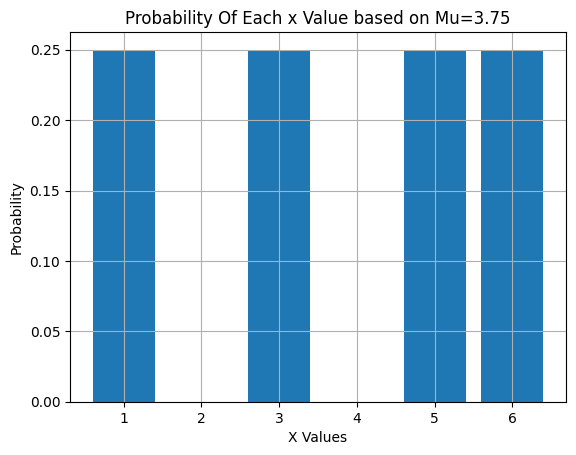

In [54]:
# do the same thing for Mu equal to artheimetic mean of X
mu = np.mean(X)
beta = calculate_beta(X, mu)
probabilities = calculate_probability(X, beta)
plt.bar(x, probabilities)
plt.grid()
plt.xlabel('X Values')
plt.ylabel('Probability')
plt.title(f'Probability Of Each x Value based on Mu={mu}')

Text(0.5, 1.0, 'Probability Of Each x Value based on Mu=2')

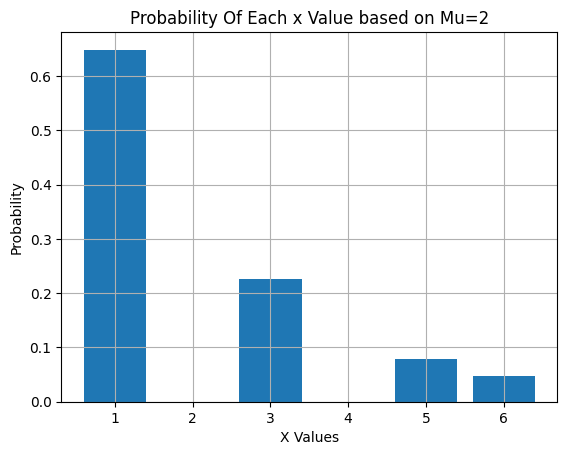

In [56]:
# do the same thing for Mu less than the artheimetic mean of X
mu = 2
beta = calculate_beta(X, mu)
probabilities = calculate_probability(X, beta)
plt.bar(x, probabilities)
plt.grid()
plt.xlabel('X Values')
plt.ylabel('Probability')
plt.title(f'Probability Of Each x Value based on Mu={mu}')


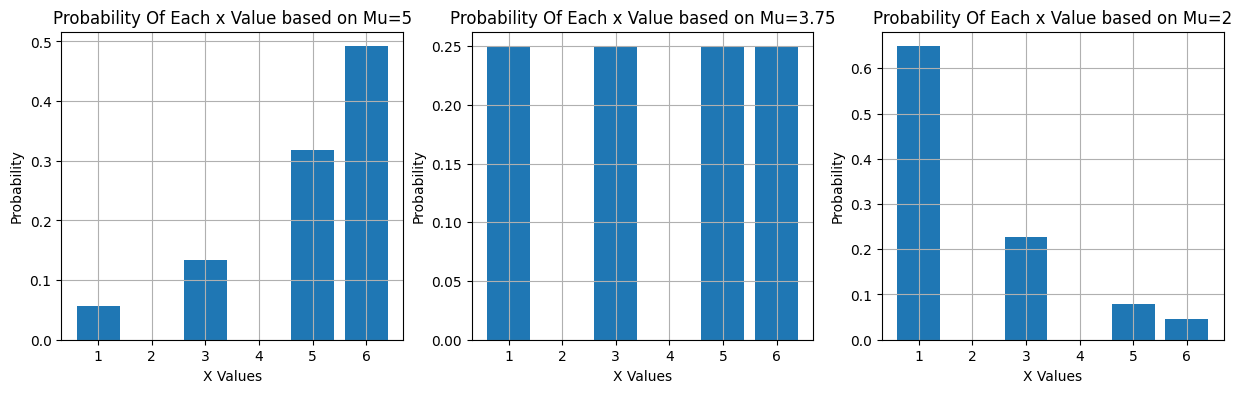

In [58]:
# plot all those above three horizontally 
plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
mu = 5
beta = calculate_beta(X, mu)
probabilities = calculate_probability(X, beta)
plt.bar(x, probabilities)
plt.grid()
plt.xlabel('X Values')
plt.ylabel('Probability')
plt.title(f'Probability Of Each x Value based on Mu={mu}')

plt.subplot(1,3,2)
mu = np.mean(X)
beta = calculate_beta(X, mu)
probabilities = calculate_probability(X, beta)
plt.bar(x, probabilities)
plt.grid()
plt.xlabel('X Values')
plt.ylabel('Probability')
plt.title(f'Probability Of Each x Value based on Mu={mu}')

plt.subplot(1,3,3)
mu = 2
beta = calculate_beta(X, mu)
probabilities = calculate_probability(X, beta)
plt.bar(x, probabilities)
plt.grid()
plt.xlabel('X Values')
plt.ylabel('Probability')
plt.title(f'Probability Of Each x Value based on Mu={mu}')
plt.show()